# 05. Local Model과 Agent 연결

에이전트는 모델을 한 번 부르고 끝나는 프로그램이 아닙니다. 모델을 부르고, 도구를 실행하고, 그 결과를 붙여 다시 부르는 일을 되풀이합니다. 이 노트북은 그 되풀이를 **서버의 자리**에서 봅니다. 서버는 에이전트가 무엇을 하는지 모르고 요청만 받습니다. 그런데도 두 번째 요청부터 빨라질 수 있는 이유는 Part 2에서 본 block hash 사슬 덕분입니다. 여기서는 그 재사용이 에이전트의 요청 모양에서 어떻게 살아남고 어떻게 깨지는지 확인합니다. 마지막으로 `Day07/task.md`와 `Day07/dcode_task.md`의 과제 1을 만들 때 무엇을 조심해야 하는지 잇습니다.

이 노트북의 코드 셀은 네트워크를 부르지 않습니다. API 키, GPU, RunPod가 없어도 끝까지 실행됩니다. 서버에 연결하는 셀은 `RUN_POD = False`로 막혀 있습니다.

## 학습 목표

- 에이전트 루프가 서버에게 어떤 요청 열(列)로 보이는지 설명한다.
- 턴마다 무엇이 재사용되고, 무엇이 재사용을 깨는지 실행 전에 예측한다.
- `create_deep_agent`가 매 턴 모델에 넘기는 것(system, tools, messages)을 기록으로 확인한다.
- `cached_tokens`를 보려면 서버와 클라이언트에 각각 어떤 조건이 필요한지 말한다.
- `cache_salt`, `reasoning` 필드, `reasoning_effort`가 요청과 응답에서 어떻게 움직이는지 설명한다.
- 확인된 주장과 미확인 주장을 구분해서 말한다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 0 | Part 4와 `04b`에서 넘어온 것 | 3 |
| 1 | 서버가 보는 에이전트 | 8 |
| 2 | prefix 재사용과 깨지는 조건 | 11 |
| 3 | `create_deep_agent`가 매 턴 보내는 것 | 12 |
| 4 | `cached_tokens`와 usage | 8 |
| 5 | `cache_salt` | 5 |
| 6 | `reasoning` 필드와 effort | 6 |
| 7 | 서버로 바꿀 때 (`RUN_POD`) | 3 |
| 8 | 직접 해보기, 확인 질문, 정리 | 4 |

## 호출 규모

모델 호출 0회, 유료 API 호출 0회, 키와 GPU가 필요 없습니다. `create_deep_agent`는 이 노트북 안에서 정의한 가짜 chat model(네트워크 없음)로 돌립니다. `ChatOpenAI`는 `httpx.MockTransport`로 만든 가짜 서버에만 연결합니다. 설치된 `deepagents`와 `langchain-openai` 버전은 첫 코드 셀이 출력합니다.

## 0. Part 4와 `04b`에서 넘어온 것

Part 4는 가중치와 KV cache의 dtype, 곧 메모리 쪽 선택지를 다뤘습니다. 그 선택으로 같은 GPU에 더 많은 block이 들어가면 prefix cache에 오래 남을 수 있는 token도 늘어납니다. 반대로 block이 모자라면 앞 턴의 block이 먼저 밀려납니다. 이 노트북의 `pressure_evict` 시나리오가 그 모습을 작게 보여 줍니다. 이 prefix를 GPU 메모리 밖에서도 지키는 방법은 바로 앞 노트북 `04b`에서 다뤘습니다.

Part 2에서 가져올 것은 한 가지입니다. block의 hash는 "앞 block의 hash, 이 block의 token id들, 추가 key"로 만들어지므로 **앞부분이 한 글자라도 달라지면 그 뒤는 모두 다른 block**이 됩니다(P2-45, P2-47). 에이전트의 모든 이야기는 이 문장의 변주입니다.

### 수업 서버와의 차이

이 노트북의 코드 경로는 vLLM v0.32.0의 Python frontend 기준입니다. 수업 Pod는 `Day07/README.md:75`에 따르면 v0.28.1rc1 dev 빌드이고(R-01), GLM-5.3-Flash 레시피의 기본 명령은 Rust frontend를 켭니다(P1-49). 수업 Pod가 어느 frontend로 떴는지, 어떤 서버 플래그로 떴는지는 기록이 없습니다. 그래서 이 노트북은 "수업 서버가 이렇게 동작한다"고 쓰지 않습니다. 소스에서 읽은 규칙과, 서버에 붙였을 때 직접 확인해야 하는 항목을 나눠서 적습니다.

In [1]:
import hashlib
import importlib.metadata as metadata
import json

import pandas as pd

from vllm_lab import DEFAULT_BLOCK_SIZE, VLLM_COMMIT, VLLM_VERSION, agent_sim, view

print("기준 vLLM 소스:", VLLM_VERSION, VLLM_COMMIT[:7])
print("block 크기(교육용 기본):", DEFAULT_BLOCK_SIZE)
for package in ("deepagents", "langchain-openai", "langchain-core"):
    print(f"{package} {metadata.version(package)}")
print("agent_sim이 모델링하지 않은 것:")
for sentence in agent_sim.NOT_MODELED:
    print(" -", sentence)

기준 vLLM 소스: 0.32.0 5df63a7
block 크기(교육용 기본): 16
deepagents 0.7.32
langchain-openai 1.7.3
langchain-core 1.7.3
agent_sim이 모델링하지 않은 것:
 - 실제 chat template과 실제 tokenizer는 쓰지 않습니다. 렌더링은 이 파일의 toy 규칙입니다.
 - 앞 턴의 답변이 문자열로 돌아와 다시 tokenize될 때 생기는 token 어긋남은 모델링하지 않았습니다(P5-07, 미확인).
 - 요약 middleware와 도구 인자 줄이기가 앞 messages를 바꾸는 경우는 모델링하지 않았습니다(P5-21).
 - tools를 system 뒤, messages 앞에 렌더링하는 것은 toy의 가정이고 실제 GLM-5.3-Flash template의 위치와 다릅니다(P5-08).
 - 실제 서버의 tool 파서 실행은 하지 않습니다. 파서 결과는 reference_parser.json을 읽을 때만 나옵니다.


## 1. 서버가 보는 에이전트

**개념.** 서버에게 멀티턴 대화는 없습니다. 턴마다 새 request가 하나 오고, 그 request의 `messages`에는 지금까지의 대화 전체가 다시 들어 있습니다(P5-01). 에이전트가 도구를 한 번 부르면 서버는 요청을 두 번 받습니다. 첫 번째는 모델이 `tool_calls`를 내는 요청이고, 이 요청은 거기서 정상으로 끝납니다. 두 번째는 앞 대화 뒤에 도구 결과 메시지를 붙인 **새 요청**입니다(P5-23, P6-33). 다만 응답이 `length`로 잘려서 끝난 경우는 정상 종료가 아니므로 이 흐름의 예외입니다. 서버는 두 번째 요청에서 앞 대화와 token이 같은 앞쪽 block만 prefix cache에서 다시 가져옵니다(P5-23). 어디까지 같은지는 클라이언트가 앞 대화를 어떻게 다시 보내는지에 달려 있고, 이 노트북은 그 범위를 2절과 3절에서 봅니다.

**공식 문서.** vLLM 공식 문서에는 "멀티턴은 턴마다 새 request"라는 설명이 없습니다. 이 노트북은 코드를 읽어서 확인합니다.

**코드.** 요청 본문의 대화는 `messages` 목록 하나입니다([vllm/entrypoints/openai/chat_completion/protocol.py:223](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L223)). 세션을 가리키는 필드로는 선택값 `session_id`가 있습니다([vllm/entrypoints/openai/chat_completion/protocol.py:406](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L406)). 이 값은 KV 이벤트 메타데이터로만 흘러가고([vllm/v1/core/block_pool.py:373](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L373), [vllm/v1/core/block_pool.py:560](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/block_pool.py#L560)) block hash의 입력에는 들어가지 않습니다. hash에 섞이는 추가 key는 LoRA, 멀티모달, `cache_salt`, prompt embeds뿐입니다([vllm/v1/core/kv_cache_utils.py:647](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L647)). 그래서 "vLLM에는 세션이 전혀 없다"가 아니라 "세션 필드는 있지만 재사용과는 상관이 없다"가 정확합니다(P5-02).

**왜 이렇게 설계했나.** 재사용을 세션이 아니라 prefix hash에 맡기면 서버가 대화를 기억할 필요가 없습니다. 같은 앞부분을 가진 요청이면 누가 보냈든 같은 block을 씁니다. 이 앞 문장은 이 과정의 해석입니다. 이슈 [#8779](https://github.com/vllm-project/vllm/issues/8779)(vllm-project/vllm)는 V1 구조의 방향으로 "prefix caching을 first-class 기능으로 둔다"고 적습니다. 효과 수치는 본문에 없습니다. 세션 대신 hash를 택한 이유를 밝히는 문장은 소스와 공식 문서에서 찾지 못했습니다.

In [2]:
# 에이전트 한 번 실행이 서버에는 어떤 request 열로 보이는가 (손으로 쓴 예시 대화)
SYSTEM = "You are a helpful agent."
conversation = [
    {"role": "user", "content": "notes.txt 에 메모를 쓰고 다시 읽어 줘"},
    {"role": "assistant", "content": "", "tool_calls": [{"name": "write_file", "args": {"path": "notes.txt"}}]},
    {"role": "tool", "content": "written"},
    {"role": "assistant", "content": "", "tool_calls": [{"name": "read_file", "args": {"path": "notes.txt"}}]},
    {"role": "tool", "content": "memo"},
]
request_ends = [1, 3, 5]  # 모델이 불린 시점마다 messages를 어디까지 보내는가

rows, previous = [], []
for number, end in enumerate(request_ends, start=1):
    messages = conversation[:end]
    shared = 0
    while shared < min(len(previous), len(messages)) and previous[shared] == messages[shared]:
        shared += 1
    rows.append({
        "request": number,
        "messages 역할": " > ".join(m["role"] for m in messages),
        "앞 요청과 같은 앞부분 메시지": shared,
        "새로 붙은 메시지": len(messages) - shared,
        "toy token 수": len(agent_sim.render_prompt(SYSTEM, [], messages)),
    })
    previous = messages
view.table(rows)

,request,messages 역할,앞 요청과 같은 앞부분 메시지,새로 붙은 메시지,toy token 수
0,1,user,0,1,24
1,2,user > assistant > tool,1,2,64
2,3,user > assistant > tool > assistant > tool,3,2,104


**관찰할 것.** `앞 요청과 같은 앞부분 메시지` 칸을 읽으세요. 요청마다 앞부분은 그대로이고 끝에만 메시지가 붙습니다. `toy token 수`는 요청마다 늘어납니다. 서버가 새로 계산해야 하는 양은 이 늘어난 총량이 아니라 **붙은 만큼**이어야 이상적입니다. 그렇게 되려면 서버가 앞 요청의 KV를 어딘가에 남겨 두고 있어야 하고, 그 열쇠가 다음 표의 hash 입력입니다.

In [3]:
# hash 키에 들어가는 것과 들어가지 않는 것 (v0.32.0 코드 읽기, 근거 ID 포함)
view.table([
    {"항목": "앞 block의 hash", "hash 입력": "예(첫 block은 부모가 없어 고정값 NONE_HASH)", "근거": "P5-04, P2-45"},
    {"항목": "이 block의 token id", "hash 입력": "예", "근거": "P5-04"},
    {"항목": "LoRA, 멀티모달, prompt embeds", "hash 입력": "예(해당할 때)", "근거": "P5-02"},
    {"항목": "cache_salt", "hash 입력": "예(시작 위치 0인 block에만)", "근거": "P5-09"},
    {"항목": "session_id", "hash 입력": "아니오(KV 이벤트 메타데이터로만 감)", "근거": "P5-02"},
])

,항목,hash 입력,근거
0,앞 block의 hash,예(첫 block은 부모가 없어 고정값 NONE_HASH),"P5-04, P2-45"
1,이 block의 token id,예,P5-04
2,"LoRA, 멀티모달, prompt embeds",예(해당할 때),P5-02
3,cache_salt,예(시작 위치 0인 block에만),P5-09
4,session_id,아니오(KV 이벤트 메타데이터로만 감),P5-02


## 2. prefix 재사용과 깨지는 조건

이제 재사용이 실제로 어떻게 보이는지 관찰합니다. 먼저 한 가지를 분명히 합니다. **이것은 vLLM이 아니라 수업용 모델입니다.** `agent_sim`은 문장을 단어 단위 toy token으로 바꾸고, 재사용 판정만 `kv_sim`(v0.32.0의 block hash 규칙을 옮긴 모델)에 맡깁니다. 실제 GLM의 tokenizer와 chat template은 쓰지 않았습니다. 앞 턴의 답변이 문자열로 돌아와 다시 tokenize될 때 생길 수 있는 어긋남, 요약 middleware가 앞 메시지를 줄이는 경우는 모델링하지 않았습니다. tools는 system 뒤, messages 앞에 렌더링한다고 가정할 뿐이고 실제 chat template의 위치와는 다릅니다. 아래 숫자는 "vLLM이 이렇게 동작했다"가 아니라 "규칙을 이렇게 옮기면 이렇게 나온다"입니다. 시간 값은 만들지 않았습니다.

**코드.** 기본 설정에서 prefix caching은 켜져 있고([vllm/config/cache.py:141](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L141)) 해시 알고리즘 기본값은 sha256입니다([vllm/config/cache.py:143](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L143)). 공식 문서는 켜는 방법만 적고 기본값은 적지 않습니다(P5-03). 코드가 `enable_prefix_caching`을 강제로 끄는 구성도 있습니다. non-causal attention 층이 있는 model([vllm/v1/engine/core.py:286-290](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/core.py#L286-L290))과 multi-modal encoder만 돌리는 instance([vllm/config/vllm.py:1427-1438](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L1427-L1438)) 등입니다. GLM-5.3-Flash 서버가 켜진 채로 뜨는지는 실행으로 확인하지 않았습니다. block 해시는 부모 hash, 이 block의 token, 추가 key로 만들어지고([vllm/v1/core/kv_cache_utils.py:695](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L695)), "block이 꽉 찼다고 가정"하고 계산합니다([vllm/v1/core/kv_cache_utils.py:711](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L711)). 부모가 없는 첫 block에는 부모 hash 자리에 고정값 `NONE_HASH`가 들어가고, 그 뒤 block에는 앞 block의 hash가 들어갑니다([vllm/v1/core/kv_cache_utils.py:719-724](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L719-L724)).

시나리오는 4턴입니다. 턴마다 사용자 입력이 쌓이고 앞 턴의 답변이 assistant 메시지로 되돌아옵니다.

**먼저 예측하세요.** `append_only`에서 세 번째 턴의 `hit_ratio`는 대략 얼마일까요? 0.5 아래, 0.5~0.8, 0.8 위 중에서 고르고, 이유를 "새로 붙은 부분이 전체에서 차지하는 비율"로 한 줄 적어 보세요.

In [4]:
COLUMNS = ["turn", "label", "prompt_tokens", "hit_tokens", "hit_blocks", "recomputed_tokens", "hit_ratio", "first_miss_block"]


def show(name, **kwargs):
    return view.table(agent_sim.run_scenario(name, **kwargs), COLUMNS)


show("append_only")

,turn,label,prompt_tokens,hit_tokens,hit_blocks,recomputed_tokens,hit_ratio,first_miss_block
0,1,턴 1,264,0,0,264,0.000000,0
1,2,턴 2,324,256,16,68,0.790123,16
2,3,턴 3,384,320,20,64,0.833333,20
3,4,턴 4,444,384,24,60,0.864865,24


**관찰할 것.** `hit_tokens`와 `first_miss_block` 두 칸을 읽으세요. 첫 턴은 적중 0이고, 이후 턴은 앞 턴의 꽉 찬 block만큼 적중합니다. `recomputed_tokens`가 사용자 입력과 답변 길이에 비슷하게 머무는 것도 보세요. `first_miss_block`이 숫자인 것은 상한에 닿기 전에 앞 턴과 달라지는 지점을 만났다는 뜻입니다. 앞 턴 답변이 assistant 메시지로 되돌아오는 자리가 그 block에 있습니다. 전부 같은 요청이면 이 칸은 `-`입니다(아래 상한 실험).

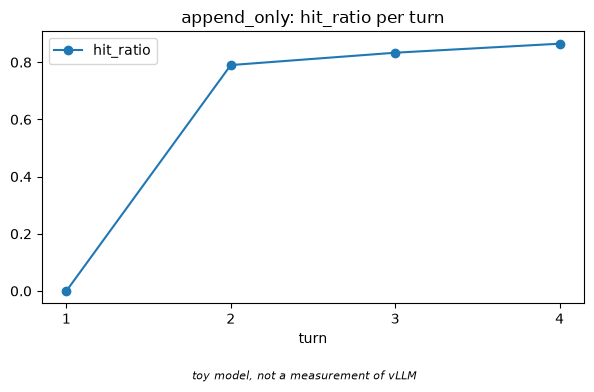

In [5]:
rows = agent_sim.run_scenario("append_only")
fig = view.sweep_chart(rows, "turn", ["hit_ratio"],
                       note="toy model, not a measurement of vLLM",
                       title="append_only: hit_ratio per turn")
from matplotlib.ticker import MaxNLocator
fig.axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
fig

**먼저 예측하세요.** 이번에는 3번째 턴부터 system prompt의 맨 앞 문장만 바꿉니다(`You are a support agent.`가 `Answer briefly.`로). 3번째 턴의 적중 token은 얼마일까요? 4번째 턴은 다시 회복될까요?

In [6]:
show("system_change")

,turn,label,prompt_tokens,hit_tokens,hit_blocks,recomputed_tokens,hit_ratio,first_miss_block
0,1,턴 1,264,0,0,264,0.000000,0
1,2,턴 2,324,256,16,68,0.790123,16
2,3,턴 3 (변경),381,0,0,381,0.000000,0
3,4,턴 4,441,368,23,73,0.834467,23


**관찰할 것.** 변경이 들어온 턴의 `hit_tokens`가 0인지 보세요. 그 다음 턴이 다시 적중하는 것은 4번째 요청이 **새 system prompt를 가진 3번째 요청**의 block을 재사용하기 때문입니다. 깨진 것은 3번째 턴 한 번이고, 이후에는 새 prefix가 자리를 잡습니다. 이것이 사슬 hash의 값입니다. 앞이 같으면 뒤를 믿을 수 있고, 앞이 다르면 뒤를 전혀 믿을 수 없습니다(P2-47).

In [7]:
frames = []
for name in ("tool_added", "tool_order_change"):
    frame = show(name)
    frame.insert(0, "시나리오", name)
    frames.append(frame)
pd.concat(frames, ignore_index=True)

,시나리오,turn,label,prompt_tokens,hit_tokens,hit_blocks,recomputed_tokens,hit_ratio,first_miss_block
0,tool_added,1,턴 1,264,0,0,264,0.000000,0
1,tool_added,2,턴 2,324,256,16,68,0.790123,16
2,tool_added,3,턴 3 (변경),468,208,13,260,0.444444,13
3,tool_added,4,턴 4,528,464,29,64,0.878788,29
4,tool_order_change,1,턴 1,264,0,0,264,0.000000,0
5,tool_order_change,2,턴 2,324,256,16,68,0.790123,16
6,tool_order_change,3,턴 3 (변경),384,48,3,336,0.125000,3
7,tool_order_change,4,턴 4,444,384,24,60,0.864865,24


**tool 목록을 바꾸는 경우는 모델의 가정과 실제 chat template이 다릅니다.** 이 표에서 변경 턴의 적중이 부분적으로 남는 것은 `agent_sim`이 tools를 system 뒤, messages 앞에 렌더링한다고 **가정**했기 때문입니다. 실제 GLM-5.3-Flash chat template은 tool 정의를 system 메시지보다 앞에 렌더링합니다([chat_template.jinja:33-47](https://huggingface.co/zai-org/GLM-5.3-Flash/blob/46a050bec13002ad29ee795c16e61cf4fa3c4a9c/chat_template.jinja#L33-L47), system은 [chat_template.jinja:252](https://huggingface.co/zai-org/GLM-5.3-Flash/blob/46a050bec13002ad29ee795c16e61cf4fa3c4a9c/chat_template.jinja#L252)). 이 판단은 서버를 돌린 결과가 아니라 Hugging Face 체크포인트 `zai-org/GLM-5.3-Flash`의 chat template(revision 46a050b)을 진짜 tokenizer로 렌더링한 구성 문자열 비교입니다. 수업 Pod가 같은 revision의 template을 쓰는지는 모릅니다. 사람이 만든 208 token 대화에서 0부터 센 첫 차이 위치는 tool 순서를 바꾸면 50번째 token(block 3), tool 하나를 빼면 88번째(block 5), system 문구를 바꾸면 193번째(block 12)였습니다. 그래서 이 template에서는 tool 변경이 system 변경보다 훨씬 앞에서 사슬을 끊고, 앞 block만 재사용됩니다. 서버가 tool 순서를 정렬해 주지도 않습니다. Python frontend는 `render_chat`([vllm/renderers/online_renderer.py:282-287](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/online_renderer.py#L282-L287))에서 요청 순서 그대로 dump해 `tokenizer.apply_chat_template`([vllm/renderers/hf.py:826-830](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/hf.py#L826-L830))에 넘깁니다. 레시피 기본 명령의 Rust frontend는 읽지 않았습니다. **수업의 권장.** 대화 도중에 tool 목록을 바꾸지 말고, 순서도 고정하세요.

In [8]:
show("effort_in_system")

,turn,label,prompt_tokens,hit_tokens,hit_blocks,recomputed_tokens,hit_ratio,first_miss_block
0,1,턴 1,268,0,0,268,0.000000,0
1,2,턴 2,328,256,16,72,0.780488,16
2,3,턴 3 (변경),388,48,3,340,0.123711,3
3,4,턴 4,448,384,24,64,0.857143,24


**effort 값은 실제 template에서 맨 앞에 들어갑니다.** 레시피는 `reasoning_effort` 값이 prompt에 `Reasoning Effort: ...`로 들어간다고 적습니다. 위 시나리오는 그 서술을 system 끝에 붙여 본 가정이어서, 변경 턴에서 첫 몇 block이 남았습니다. 실제 GLM-5.3-Flash chat template은 값이 low나 high가 아니면 max로 두고, prompt 맨 앞에 effort 줄을 넣습니다([chat_template.jinja:2-3](https://huggingface.co/zai-org/GLM-5.3-Flash/blob/46a050bec13002ad29ee795c16e61cf4fa3c4a9c/chat_template.jinja#L2-L3)). 서버는 `chat_template_kwargs`에서 template이 선언한 변수, tokenizer `apply_chat_template`의 이름 있는 인자, HF 기본 인자만 통과시킵니다([vllm/renderers/hf.py:715-743](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/hf.py#L715-L743)). revision 46a050b의 template을 진짜 tokenizer로 렌더링한 구성 문자열 비교에서 low, high, max는 0부터 센 8번째 token에서 갈라졌고, 이는 첫 block 안입니다. 이 구성에서 `medium`은 max와 같은 문자열이었습니다. 그러므로 이 template에서는 effort를 low, high, max 사이에서 바꾸면 이전 값으로 쌓은 block을 하나도 재사용하지 못합니다. 위 toy 표에서 앞 block이 남은 것은 가정한 위치 때문이고 실제는 더 나쁩니다. 이 결론은 template 렌더링 비교이고 서버의 `cached_tokens`를 측정한 것이 아닙니다. 수업 Pod의 template revision은 모릅니다(P5-13).

In [9]:
show("pressure_evict")

,turn,label,prompt_tokens,hit_tokens,hit_blocks,recomputed_tokens,hit_ratio,first_miss_block
0,1,턴 1,264,0,0,264,0.000000,0
1,2,filler (다른 요청),480,0,0,480,0.000000,0
2,3,턴 2,324,16,1,308,0.049383,1
3,4,filler (다른 요청),480,160,10,320,0.333333,10
4,5,턴 3,384,16,1,368,0.041667,1
5,6,filler (다른 요청),480,96,6,384,0.200000,6
6,7,턴 4,444,16,1,428,0.036036,1


**관찰할 것.** `label`이 `filler (다른 요청)`인 행은 사이에 끼어든 다른 요청입니다. 에이전트의 턴 행에서 `hit_tokens`가 첫 턴 이후에도 작게 머무는지 보세요. pool이 작아서 앞 턴의 block이 다른 요청의 할당 때문에 밀려난 것입니다. eviction은 별도 단계가 아니라 새 block이 필요할 때 free queue 앞에서 꺼내면서 일어나고(P2-41), 한 번 밀려난 block의 뒤는 사슬이 끊겨 함께 쓸모를 잃습니다(P2-45). 이 모델은 블록 수를 일부러 줄여 그 효과를 크게 보여 줍니다. 실제 서버에서 얼마나 자주 일어나는지는 이 표로 알 수 없습니다.

In [10]:
# 조회 상한 실험: 전부 같은 prompt를 두 번 보내도 한 block이 다시 계산된다
fixed = len(agent_sim.render_prompt("", [], [{"role": "user", "content": ""}]))
words = " ".join(f"w{i}" for i in range(DEFAULT_BLOCK_SIZE * 6 - fixed))  # 정확히 6 block
sim = agent_sim.AgentReuseSim()
for label in ("첫 요청", "똑같은 요청"):
    sim.send("", [], [{"role": "user", "content": words}], label=label)
shown = [{**r, "first_miss_block": "-" if r["first_miss_block"] is None else str(r["first_miss_block"])}
         for r in sim.rows()]
view.table(shown, COLUMNS)

,turn,label,prompt_tokens,hit_tokens,hit_blocks,recomputed_tokens,hit_ratio,first_miss_block
0,1,첫 요청,96,0,0,96,0.000000,0
1,2,똑같은 요청,96,80,5,16,0.833333,-


**관찰할 것.** 두 번째 행의 `prompt_tokens`는 block 크기의 정확한 배수인데도 `hit_tokens`가 그보다 한 block 작습니다. 서버는 전부 맞아도 마지막 token의 logits를 얻기 위해 최소 한 token을 다시 계산해야 하고, 조회 상한이 `request.num_tokens - 1`로 잡혀 있기 때문입니다([vllm/v1/core/kv_cache_manager.py:295](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L295)). 소스 주석은 이 상한이 block 정렬 때문에 한 block 전체의 재계산으로 이어질 수 있다고 적습니다([vllm/v1/core/kv_cache_manager.py:289](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L289)). 블로그는 이 경우를 말하지 않으므로 코드 전용 근거입니다(P5-06, P2-30). 꽉 차지 않은 마지막 block은 상한과는 다른 이유로 다시 계산됩니다. hash는 꽉 찬 block에만 만들어지고, block 크기와 hash block 크기가 같은 기본 설정에서는 부분 tail block을 따로 등록하지 않습니다([vllm/v1/core/single_type_kv_cache_manager.py:845-847](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/single_type_kv_cache_manager.py#L845-L847)). 등록 범위에는 생성된 답변 token도 들어가므로(`cache_blocks` 호출, [vllm/v1/core/kv_cache_manager.py:612-616](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_manager.py#L612-L616)) 다음 턴이 앞 턴 끝에서 다시 계산하는 것은 그 마지막 1~15 token입니다. 최대 15는 이 tail에서 나온 값이고 조회 상한에서 나온 값이 아닙니다. 같은 prompt를 block 배수 길이로 다시 보낼 때만 상한 때문에 한 block 16 token 전체를 다시 계산합니다(P5-05, P5-06, P2-43).

In [11]:
view.table([
    {"깨는 조건": "꽉 차지 않은 마지막 block (앞 턴 끝의 1~15 token)", "상태": "확정", "근거": "P5-05, P2-43"},
    {"깨는 조건": "전부 맞아도 상한 때문에 다시 계산 (길이가 block 배수이면 16 token)", "상태": "확정", "근거": "P5-06, P2-30"},
    {"깨는 조건": "어긋난 token이 든 block과 그 뒤", "상태": "확정", "근거": "P2-45, P5-04"},
    {"깨는 조건": "system prompt 변경", "상태": "확정", "근거": "P2-47"},
    {"깨는 조건": "eviction", "상태": "확정", "근거": "P2-41, P2-45"},
    {"깨는 조건": "답변 재tokenize 어긋남, 턴 경계 특수 token", "상태": "미확인 (실제 모델 출력의 재tokenize는 확인 못 함)", "근거": "P5-07(미확인), P2-46(미확인)"},
    {"깨는 조건": "tool 목록 변경, 순서 변경", "상태": "일치 (GLM template 구성 문자열: tool이 system보다 앞이라 block 3~5에서 끊김, toy는 system 뒤로 가정)", "근거": "P5-08"},
    {"깨는 조건": "effort 값 변경", "상태": "일치 (GLM template 구성 문자열: 맨 앞 줄이라 low, high, max 전환은 첫 block부터)", "근거": "P5-13"},
    {"깨는 조건": "reasoning을 되돌려 보내지 않는 ChatOpenAI 경로", "상태": "코드 전용 (GLM template 구성 문자열: 앞 턴 prompt가 끝나는 자리에서 어긋남)", "근거": "P5-22"},
])


,깨는 조건,상태,근거
0,꽉 차지 않은 마지막 block (앞 턴 끝의 1~15 token),확정,"P5-05, P2-43"
1,전부 맞아도 상한 때문에 다시 계산 (길이가 block 배수이면 16 token),확정,"P5-06, P2-30"
2,어긋난 token이 든 block과 그 뒤,확정,"P2-45, P5-04"
3,system prompt 변경,확정,P2-47
4,eviction,확정,"P2-41, P2-45"
5,"답변 재tokenize 어긋남, 턴 경계 특수 token",미확인 (실제 모델 출력의 재tokenize는 확인 못 함),"P5-07(미확인), P2-46(미확인)"
6,"tool 목록 변경, 순서 변경","일치 (GLM template 구성 문자열: tool이 system보다 앞이라 block 3~5에서 끊김, toy는 system 뒤로 가정)",P5-08
7,effort 값 변경,"일치 (GLM template 구성 문자열: 맨 앞 줄이라 low, high, max 전환은 첫 block부터)",P5-13
8,reasoning을 되돌려 보내지 않는 ChatOpenAI 경로,코드 전용 (GLM template 구성 문자열: 앞 턴 prompt가 끝나는 자리에서 어긋남),P5-22


**왜 이렇게 설계했나.** 이 표의 "확정" 행 중 어긋난 token, system 변경, eviction 행은 사슬 hash의 대가입니다. block 하나의 hash가 앞 block의 hash를 품고 있으므로 "앞이 같아야 뒤를 믿을 수 있다"는 성질이 공짜로 따라오고, 그 대신 앞의 어긋남이 뒤 전체로 번집니다(P2-45). 상한 규칙의 이유는 코드 주석이 직접 말합니다(P2-30). 마지막 token의 logits이 필요하다는 것입니다. 꽉 차지 않은 block 행은 hash를 꽉 찬 block에만 만들기 때문입니다(P2-43).

## 3. `create_deep_agent`가 매 턴 보내는 것

**개념.** 에이전트 프레임워크는 대화 상태를 대신 관리합니다. 그래서 개발자가 서버로 나가는 요청을 직접 볼 일이 드뭅니다. 서버 입장의 재사용은 **프레임워크가 매 턴 같은 앞부분을 만들어 주는가**에 달려 있습니다. 이 절은 네트워크 없이 그 앞부분을 직접 봅니다.

**방법.** 아래에서 `RecordingChatModel`을 정의합니다. `BaseChatModel`을 상속해 `bind_tools`로 도구 스키마를 받아 두고, `_generate`가 불릴 때마다 system 메시지, 도구 스키마, 나머지 메시지를 `calls`에 기록한 뒤 미리 정한 `AIMessage`를 돌려줍니다. `create_deep_agent(model=...)`는 이런 `BaseChatModel` 객체를 문자열처럼 해석하지 않고 그대로 받습니다(P5-19). 서버로 나가는 요청이 아니라 **모델 객체가 받는 입력**을 기록하는 것이므로, 실제 요청 본문과 같다고 말하지는 않습니다.

한 가지 주의가 있습니다. pydantic은 생성자에 넘긴 list를 복사합니다. 그래서 기록은 생성자에 넘긴 변수가 아니라 **`model.calls`** 에서 읽어야 합니다.

In [12]:
from typing import Any

from deepagents import create_deep_agent
from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.messages import AIMessage
from langchain_core.outputs import ChatGeneration, ChatResult
from langchain_core.utils.function_calling import convert_to_openai_tool
from pydantic import Field

ROLE_NAMES = {"human": "user", "ai": "assistant", "tool": "tool", "system": "system"}


class RecordingChatModel(BaseChatModel):
    """네트워크 없이 매 호출의 system, tools, messages를 기록하는 가짜 chat model."""

    script: list[AIMessage]
    calls: list[dict] = Field(default_factory=list)
    bound_tools: list[dict] = Field(default_factory=list)

    @property
    def _llm_type(self) -> str:
        return "recording"

    def bind_tools(self, tools, **kwargs):
        copy = self.model_copy()  # 얕은 복사라 calls 목록은 원본과 같은 객체를 공유한다
        copy.bound_tools = [convert_to_openai_tool(tool) for tool in tools]
        return copy

    def _generate(self, messages, stop=None, run_manager=None, **kwargs: Any) -> ChatResult:
        system = "".join(m.content for m in messages if m.type == "system")
        rest = []
        for message in messages:
            if message.type == "system":
                continue
            entry = {"role": ROLE_NAMES.get(message.type, message.type),
                     "content": message.content if isinstance(message.content, str) else json.dumps(message.content)}
            if getattr(message, "tool_calls", None):
                entry["tool_calls"] = message.tool_calls
            rest.append(entry)
        self.calls.append({"system": system, "tools": self.bound_tools, "messages": rest})
        return ChatResult(generations=[ChatGeneration(message=self.script[len(self.calls) - 1])])


def tool_call(name, args, call_id):
    return AIMessage(content="", tool_calls=[{"name": name, "args": args, "id": call_id}])


SCRIPT = [
    tool_call("write_file", {"file_path": "/notes.txt", "content": "prefix cache memo"}, "call-1"),
    tool_call("read_file", {"file_path": "/notes.txt"}, "call-2"),
    AIMessage(content="notes.txt 에 메모를 쓰고 다시 읽었습니다."),
]
print("정의 완료. 스크립트 길이:", len(SCRIPT))

정의 완료. 스크립트 길이: 3


**먼저 예측하세요.** 위 스크립트는 도구 호출 둘과 최종 답변 하나입니다. 모델은 몇 번 불릴까요? 그리고 두 번째 호출에서 모델이 받는 `messages`는 첫 호출의 것과 어떤 관계일까요? 모델 호출 횟수와 `tools` 개수를 적어 보세요.

In [13]:
model = RecordingChatModel(script=SCRIPT)
agent = create_deep_agent(model=model, tools=[])
result = agent.invoke({"messages": [{"role": "user", "content": "notes.txt 에 메모를 쓰고 다시 읽어 줘"}]})

print("deepagents", metadata.version("deepagents"))
print("모델이 불린 횟수:", len(model.calls))
print("마지막 답변:", result["messages"][-1].content)

deepagents 0.7.32
모델이 불린 횟수: 3
마지막 답변: notes.txt 에 메모를 쓰고 다시 읽었습니다.


In [14]:
rows = []
for number, call in enumerate(model.calls, start=1):
    rows.append({
        "호출": number,
        "system 글자 수": len(call["system"]),
        "tools 개수": len(call["tools"]),
        "messages 개수": len(call["messages"]),
        "messages 역할": " > ".join(m["role"] for m in call["messages"]),
    })
print("기록된 도구:", [tool["function"]["name"] for tool in model.calls[0]["tools"]])
view.table(rows)

기록된 도구: ['ls', 'read_file', 'write_file', 'edit_file', 'delete', 'glob', 'grep', 'task']


,호출,system 글자 수,tools 개수,messages 개수,messages 역할
0,1,0,8,1,user
1,2,0,8,3,user > assistant > tool
2,3,0,8,5,user > assistant > tool > assistant > tool


**관찰할 것.** 기록된 도구 목록과 `system 글자 수`를 읽으세요. 기본 구성에서 system 메시지는 빈 문자열이고, 도구 사용 안내문은 따로 넣지 않으며 도구 스키마의 설명에 맡깁니다(P5-20). system이 비어 있으므로 모델 객체가 받는 입력에서 크게 차지하는 것은 도구 스키마입니다. 실제 GLM-5.3-Flash chat template은 tool 정의를 system 메시지보다 앞에 렌더링합니다(P5-08). 이는 template을 렌더링해 본 결과이고 서버 출력이 아닙니다. `messages 역할` 열에서는 호출이 늘 때마다 `assistant`와 `tool`이 하나씩 붙습니다. tool call을 낸 요청은 거기서 끝나고, 다음 요청은 그 뒤에 결과를 붙인 새 요청입니다(P5-23).

In [15]:
def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()[:12]


rows = []
for number, call in enumerate(model.calls, start=1):
    previous = model.calls[number - 2]["messages"] if number > 1 else []
    rows.append({
        "호출": number,
        "system sha256": digest(call["system"]),
        "tools sha256": digest(call["tools"]),
        "앞 호출의 messages로 시작하는가": call["messages"][:len(previous)] == previous,
    })
frame = view.table(rows)
print("system이 모든 호출에서 같은가:", frame["system sha256"].nunique() == 1)
print("tools가 모든 호출에서 같은가:", frame["tools sha256"].nunique() == 1)
frame

system이 모든 호출에서 같은가: True
tools가 모든 호출에서 같은가: True


,호출,system sha256,tools sha256,앞 호출의 messages로 시작하는가
0,1,12ae32cb1ec0,aede319363e7,True
1,2,12ae32cb1ec0,aede319363e7,True
2,3,12ae32cb1ec0,aede319363e7,True


**관찰할 것.** 세 호출에서 두 sha256 열이 같은지, 마지막 열이 모두 `True`인지 읽으세요. 이 기본 구성에서는 system과 tools가 바이트 단위로 안정적이고 messages는 덧붙기만 합니다. 서버의 prefix 재사용에 유리한 모양입니다. 이 확인은 **이 구성에서 이 호출 열에 대한 것**입니다. 기록된 실측에서는 별도 프로세스 두 번 사이에서도 같았습니다(P5-21). 그러나 긴 실행에서는 앞쪽 messages가 바뀝니다. `ChatOpenAI`처럼 model profile이 없으면 요약 middleware의 기본값은 token 170000이고, 도구 인자 줄이기는 20 messages에서 시작합니다(`deepagents/middleware/summarization.py:290-316`). 줄이는 대상은 `write_file`, `edit_file`의 인자이고 길이 상한은 2000자입니다(`:745-755`, `:1170`). 가짜 서버로 2000자가 넘는 `write_file` 인자를 쓰게 한 실측에서는 system을 포함해 24개 messages인 요청부터 요청마다 앞쪽 assistant 메시지의 인자가 줄어, 그 지점에서 앞부분이 달라졌습니다. 요약 자체가 발동하는 경우와 skills, memory 내용이 바뀌는 경우(memory 갱신이 system prompt를 바꾼다는 `deepagents/graph.py:944-946`의 주석)는 실행하지 않았습니다.

**먼저 예측하세요.** 이 기록을 `agent_sim`의 toy 렌더러에 그대로 넣어 보겠습니다. 두 번째 호출의 `hit_ratio`는 높을까요, 낮을까요? 앞 표의 도구 8개를 생각하고 답하세요.

In [16]:
view.table(agent_sim.reuse_from_recorded(model.calls), COLUMNS + ["assumption"])

,turn,label,prompt_tokens,hit_tokens,hit_blocks,recomputed_tokens,hit_ratio,first_miss_block,assumption
0,1,기록 1,3048,0,0,3048,0.000000,0,"toy 렌더링 가정, 실제 template과 tool 위치가 다름(P5-08)"
1,2,기록 2,3122,3040,190,82,0.973735,190,"toy 렌더링 가정, 실제 template과 tool 위치가 다름(P5-08)"
2,3,기록 3,3193,3120,195,73,0.977137,195,"toy 렌더링 가정, 실제 template과 tool 위치가 다름(P5-08)"


**관찰할 것.** 두 번째 호출 이후 `hit_ratio`와 `recomputed_tokens`를 보세요. 도구 스키마가 길어서 앞부분이 크고, 그 뒤에 메시지 몇 개가 붙을 뿐이라 높게 나옵니다. 마지막 칸 `assumption`은 이 결과가 toy 렌더링 가정 위에 있다고 알려 줍니다. toy는 tools를 system 뒤에 두지만 실제 GLM-5.3-Flash chat template은 tool 정의를 system 메시지보다 앞에 렌더링합니다(P5-08, 앞의 tool 목록 설명).

**reasoning을 되돌려 보내지 않을 때.** `ChatOpenAI`는 다음 턴 요청을 만들 때 assistant 메시지에 `reasoning`을 다시 싣지 않았습니다(기록된 실측: `content`, `role`, `tool_calls`만). 서버는 요청 쪽 `reasoning`을 받아 template에 넘길 수 있지만([vllm/renderers/chat_utils.py:2110-2114](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/chat_utils.py#L2110-L2114)) 클라이언트가 보내지 않습니다. 그러면 GLM-5.3-Flash chat template은 그 자리를 `<think></think>`로 렌더링합니다([chat_template.jinja:143-153](https://huggingface.co/zai-org/GLM-5.3-Flash/blob/46a050bec13002ad29ee795c16e61cf4fa3c4a9c/chat_template.jinja#L143-L153)). revision 46a050b의 template을 진짜 tokenizer로 렌더링한 구성 문자열 비교에서(앞 턴 prompt 166 token에 구성한 생성 22 token을 이은 열과 비교), reasoning이 없으면 다음 턴은 166번째 token, 곧 앞 턴 prompt가 끝나는 자리에서 처음 갈라졌습니다. 생성 당시에는 그 자리에 `<think>` 뒤로 생각이 이어졌기 때문입니다. 그래서 이 경로의 재사용은 앞 턴 prompt 안의 꽉 찬 block까지(166 token이면 160 token)이고 앞 턴 답변 구간은 다시 계산합니다. 도구 호출 턴도 같습니다. openai SDK로 `reasoning`을 다시 보내면 `clear_thinking`이 거짓일 때 188번째까지(답변까지) 일치하고, 참이면 마지막 user 앞 턴의 생각이 비워져 다시 166번째에서 갈라집니다. 이것은 Python frontend와 구성 문자열 기준이며 서버 측정이 아닙니다. 수업 Pod의 template revision은 모릅니다(P5-22).

### 이 절을 `Day07/task.md`와 잇기

`Day07/task.md`는 GLM-5.3-Flash(RunPod)와 EXA 도구로 DeepAgents 하나를 만드는 과제입니다(`Day07/task.md:2-8`). `Day07/dcode_task.md:27`의 과제 1 "Prompt Caching 을 고려한 DeepAgents 구성"과 비슷한 문구가 `Day07/README.md:61`에 있습니다. 이 노트북은 그 파일들을 고치지 않습니다. **수업의 권장** 점검 순서만 정리합니다.

1. 에이전트를 만든 뒤 위의 `RecordingChatModel` 방식으로 system과 tools의 해시가 호출 사이에서 같은지 먼저 본다.
2. 시간, 요청 번호, 사용자 이름처럼 매번 바뀌는 값을 system prompt 앞쪽에 넣지 않는다.
3. 도구를 대화 도중에 추가하거나 순서를 바꾸지 않는다(이 template에서 tool 정의는 system보다 앞이라 변경이 앞쪽 block에서 끊습니다, P5-08).
4. deepagents가 갖고 있는 prompt caching middleware(Anthropic, Bedrock, Fireworks용)는 해당 모델이 아니면 아무것도 하지 않습니다(`graph.py` 주석, P5-25). **서버 쪽 prefix cache는 그 middleware와 별개로 동작합니다.** 두 장치를 같은 것으로 소개하지 않습니다.

## 4. `cached_tokens`와 usage

**개념.** 재사용이 일어나는지 눈으로 확인하려면 응답의 `usage.prompt_tokens_details.cached_tokens`를 봅니다. 그런데 이 값이 응답에 실리는 조건은 서버 플래그 하나에, 스트리밍일 때의 조건이 더해집니다.

1. **서버 플래그.** `--enable-prompt-tokens-details`가 있어야 합니다. 기본값은 False라서([vllm/entrypoints/launchers/cli_args.py:148](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/cli_args.py#L148)) 없으면 `prompt_tokens_details`가 null입니다. 켜져 있어도 캐시 적중 token 수와 멀티모달 값이 모두 없으면 null입니다. 함수가 플래그를 보고 null을 돌려주는 곳은 [vllm/entrypoints/openai/chat_completion/serving.py:90-104](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L90-L104)이고, 비스트리밍 응답을 채우는 곳은 [vllm/entrypoints/openai/chat_completion/serving.py:1164](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L1164)입니다. 응답 필드의 정의는 [vllm/entrypoints/serve/engine/protocol.py:121](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/serve/engine/protocol.py#L121)에 있습니다(P5-11).
2. **스트리밍이면 usage 요청.** 스트리밍에서는 요청에 `stream_options.include_usage`를 실어야 마지막 usage 청크가 옵니다. 서버가 `--enable-force-include-usage`([vllm/entrypoints/launchers/cli_args.py:154](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/launchers/cli_args.py#L154))로 강제할 수도 있고, 이때는 `include_usage`와 매 청크 usage가 함께 켜집니다. 판정 함수 `should_include_usage`는 [vllm/entrypoints/serve/utils/api_utils.py:289-301](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/serve/utils/api_utils.py#L289-L301)이고, 최종 usage에 세부 정보를 붙이는 곳은 [vllm/entrypoints/openai/chat_completion/serving.py:853-858](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/serving.py#L853-L858)입니다. 어느 쪽이든 그 usage 청크에 `cached_tokens`가 실리려면 1번의 서버 플래그도 필요합니다(P5-12).
3. **클라이언트 설정.** `ChatOpenAI`에 `base_url`을 주면 `stream_usage`가 켜지지 않아 `stream_options`가 요청에 실리지 않습니다. `stream_usage=True`를 직접 줘야 합니다(P5-17). 받은 값은 `usage_metadata["input_token_details"]["cache_read"]`로 옮겨집니다.

**공식 문서.** 공식 문서에서 `--enable-prompt-tokens-details` 설명은 찾지 못했습니다. 코드가 유일한 근거입니다. 그리고 수업 Pod가 이 플래그를 켰는지는 `Day07/README.md`와 두 스크립트 어디에도 기록이 없습니다.

In [17]:
rows = []
for server_flag in (False, True):
    for stream, stream_usage in ((False, None), (True, None), (True, True)):
        sends = agent_sim.chatopenai_sends_include_usage(base_url_set=True, stream_usage=stream_usage)
        for force in (False, True):
            if force and not stream:
                continue
            verdict = agent_sim.cached_tokens_visible(server_flag=server_flag, stream=stream,
                                                      client_sends_include_usage=sends, force_include_usage=force)
            rows.append({
                "서버 --enable-prompt-tokens-details": server_flag,
                "스트리밍": stream,
                "ChatOpenAI stream_usage": stream_usage,
                "클라이언트가 include_usage를 보냄": sends,
                "서버가 usage 강제": force,
                "cached_tokens 보임": verdict["visible"],
                "이유": verdict["why"],
            })
view.table(rows)

,서버 --enable-prompt-tokens-details,스트리밍,ChatOpenAI stream_usage,클라이언트가 include_usage를 보냄,서버가 usage 강제,cached_tokens 보임,이유
0,False,False,-,False,False,False,서버에 --enable-prompt-tokens-details가 없으면 prompt_tokens_details가 null입니다(P5-11).
1,False,True,-,False,False,False,서버에 --enable-prompt-tokens-details가 없으면 prompt_tokens_details가 null입니다(P5-11).
2,False,True,-,False,True,False,서버에 --enable-prompt-tokens-details가 없으면 prompt_tokens_details가 null입니다(P5-11).
3,False,True,True,True,False,False,서버에 --enable-prompt-tokens-details가 없으면 prompt_tokens_details가 null입니다(P5-11).
4,False,True,True,True,True,False,서버에 --enable-prompt-tokens-details가 없으면 prompt_tokens_details가 null입니다(P5-11).
5,True,False,-,False,False,True,서버 플래그가 켜져 있고 usage가 응답에 실립니다.
6,True,True,-,False,False,False,스트리밍은 stream_options.include_usage를 보내거나 서버가 강제해야 usage 청크가 옵니다(P5-12).
7,True,True,-,False,True,True,서버 플래그가 켜져 있고 usage가 응답에 실립니다.
8,True,True,True,True,False,True,서버 플래그가 켜져 있고 usage가 응답에 실립니다.
9,True,True,True,True,True,True,서버 플래그가 켜져 있고 usage가 응답에 실립니다.


**관찰할 것.** `cached_tokens 보임`이 `True`가 되는 행의 조건을 찾으세요. 서버 플래그 칸이 `False`인 행은 다른 칸이 아무리 좋아도 전부 `False`입니다. 스트리밍 행에서는 `stream_usage`가 `None`인 클라이언트가 `include_usage`를 보내지 않는다는 점이 두 번째 함정입니다. 이 표는 근거 행의 규칙을 옮긴 판정 함수의 출력이고 서버에서 확인한 값이 아닙니다. 표의 `-`는 값이 없다(`None`)는 뜻으로, `ChatOpenAI stream_usage` 칸의 `-`는 인자를 주지 않은 기본값입니다.

In [18]:
# 실패 재현: base_url을 준 ChatOpenAI는 스트리밍 usage를 요청하지 않는다 (호출 없이 설정값만 본다)
from langchain_openai import ChatOpenAI

FAKE = {"base_url": "http://fake-server.invalid/v1"}  # 존재하지 않는 주소, 접속하지 않는다
clients = {
    "stream_usage 기본값": ChatOpenAI(model="local", api_key="unused", **FAKE),
    "stream_usage=True": ChatOpenAI(model="local", api_key="unused", stream_usage=True, **FAKE),
}
for name, client in clients.items():
    sends = agent_sim.chatopenai_sends_include_usage(base_url_set=True, stream_usage=client.stream_usage)
    verdict = agent_sim.cached_tokens_visible(server_flag=True, stream=True, client_sends_include_usage=sends)
    print(f"{name:<20} stream_usage 속성={client.stream_usage!r:<6} include_usage 전송={sends!s:<6} cached_tokens 보임={verdict['visible']}")
print("서버 플래그를 켠 서버 + 스트리밍이어도 기본값 클라이언트는 False로 끝난다. 예외는 나지 않는다.")

stream_usage 기본값     stream_usage 속성=None   include_usage 전송=False  cached_tokens 보임=False
stream_usage=True    stream_usage 속성=True   include_usage 전송=True   cached_tokens 보임=True
서버 플래그를 켠 서버 + 스트리밍이어도 기본값 클라이언트는 False로 끝난다. 예외는 나지 않는다.


**관찰할 것.** 두 줄을 나란히 읽으세요. 틀린 값(기본값 클라이언트의 `False`)과 맞는 값(`stream_usage=True`의 `True`)이 같은 서버 조건에서 갈립니다. 오류 메시지가 없다는 점이 이 실패의 성격입니다. 그냥 `cached_tokens`가 비어 있을 뿐입니다. 그래서 "`cached_tokens`가 null이면 무엇부터 확인하나"의 답은 서버 플래그, 그다음 스트리밍 여부와 `include_usage`, 마지막으로 클라이언트의 `stream_usage` 순입니다.

다음 셀은 `httpx.MockTransport`로 만든 가짜 서버에 `ChatOpenAI`를 연결해서, 클라이언트가 **실제로 어떤 요청 본문을 보내는지** 봅니다. 이 가짜 서버는 이 노트북 안에서 정의한 것이고, "요청에 `include_usage`가 있으면 usage 청크를 붙인다"는 규칙(P5-12)을 흉내 낼 뿐 vLLM이 아닙니다. 네트워크는 쓰지 않습니다.

In [19]:
import httpx


def fake_server(log):
    """요청 본문을 log에 모으고, 규칙에 맞는 가짜 응답을 돌려주는 httpx.Client."""
    usage = {"prompt_tokens": 100, "completion_tokens": 10, "total_tokens": 110,
             "prompt_tokens_details": {"cached_tokens": 64}}

    def chunk(delta, finish=None, with_usage=None):
        data = {"id": "x", "object": "chat.completion.chunk", "created": 0, "model": "local",
                "choices": [] if delta is None else [{"index": 0, "delta": delta, "finish_reason": finish}]}
        if with_usage:
            data["usage"] = with_usage
        return "data: " + json.dumps(data, ensure_ascii=False) + "\n\n"

    def handler(request):
        body = json.loads(request.content)
        log.append(body)
        if not body.get("stream"):
            message = {"role": "assistant", "content": "답변입니다.", "reasoning": "생각입니다."}
            return httpx.Response(200, json={
                "id": "x", "object": "chat.completion", "created": 0, "model": "local",
                "choices": [{"index": 0, "message": message, "finish_reason": "stop"}], "usage": usage})
        text = chunk({"role": "assistant", "reasoning": "생각"}) + chunk({"content": "답변"}) + chunk({}, "stop")
        if (body.get("stream_options") or {}).get("include_usage"):
            text += chunk(None, with_usage=usage)
        return httpx.Response(200, content=(text + "data: [DONE]\n\n").encode(),
                              headers={"content-type": "text/event-stream"})

    return httpx.Client(transport=httpx.MockTransport(handler))


def observe(**client_kwargs):
    log = []
    client = ChatOpenAI(model="local", api_key="unused", http_client=fake_server(log), **FAKE, **client_kwargs)
    reply = client.invoke("안녕")
    streamed = None
    for piece in client.stream("안녕"):
        streamed = piece if streamed is None else streamed + piece
    return log, reply, streamed


rows = []
for name, kwargs in (("기본값", {}), ("stream_usage=True", {"stream_usage": True})):
    log, reply, streamed = observe(**kwargs)
    rows.append({
        "클라이언트": name,
        "스트림 요청의 stream_options": log[1].get("stream_options"),
        "비스트리밍 cache_read": (reply.usage_metadata or {}).get("input_token_details", {}).get("cache_read"),
        "스트리밍 input_token_details": (streamed.usage_metadata or {}).get("input_token_details"),
    })
view.table(rows)

,클라이언트,스트림 요청의 stream_options,비스트리밍 cache_read,스트리밍 input_token_details
0,기본값,-,64,-
1,stream_usage=True,{'include_usage': True},64,{'cache_read': 64}


**관찰할 것.** `스트림 요청의 stream_options` 칸과 `스트리밍 input_token_details` 칸이 짝으로 움직이는지 보세요. 비스트리밍은 응답에 usage가 있으면 바로 들어오고(`cache_read`가 채워짐), 스트리밍은 `include_usage`가 있을 때만 들어옵니다. 표의 `-`는 값이 없음(`None`)입니다. 이 셀은 가짜 서버로 확인된 동작(P5-17)을 이 환경에서 다시 본 것입니다. 서버 쪽 `enable_prompt_tokens_details`는 기본 False이고 켜져 있어도 값이 모두 없으면 null이며(P5-11), 클라이언트의 `stream_usage` 판단은 `langchain_openai/chat_models/base.py:1844-1862`에 있습니다.

## 5. `cache_salt`

**개념.** prefix cache는 같은 앞부분을 가진 요청이면 누구에게든 재사용을 허용합니다. 서로 모르는 사용자가 한 서버를 쓰면 이 성질이 정보 노출 경로가 될 수 있습니다. `cache_salt`는 요청마다 붙이는 문자열로, 값이 다르면 서로의 block을 쓰지 못하게 합니다.

**공식 문서.** 두 문서가 이 필드를 설명합니다. 설계 문서는 요청별 salt로 prefix cache 재사용을 격리할 수 있다고 적고([docs/design/prefix_caching.md:87](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/design/prefix_caching.md#L87)), 보안 문서는 salt가 첫 KV block의 hash에 섞여 같은 salt를 가진 요청만 그 cache를 쓸 수 있다고 적습니다([docs/usage/security.md:596](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/usage/security.md#L596)). 문서의 보안 절이 격리를 목적으로 밝히므로 이유 문장은 확인됩니다(P5-09).

**코드.** 필드는 [vllm/entrypoints/openai/chat_completion/protocol.py:485](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L485)에 있고, 검증 호출은 [vllm/entrypoints/openai/chat_completion/protocol.py:548](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L548)에 있습니다. salt는 시작 위치 0인 block의 추가 key에만 들어갑니다([vllm/v1/core/kv_cache_utils.py:647](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L647)). 첫 block의 hash가 달라지면 그 값을 부모로 삼는 뒤 block도 모두 달라지므로 **다른 salt는 어떤 block도 공유하지 못합니다**(P2-28). 비용이 있습니다. 사용자마다 다른 salt를 주면 모든 사용자가 같은 system prompt를 써도 그 재사용이 사라집니다.

In [20]:
show("salt_change")

,turn,label,prompt_tokens,hit_tokens,hit_blocks,recomputed_tokens,hit_ratio,first_miss_block
0,1,턴 1,264,0,0,264,0.000000,0
1,2,턴 2,324,256,16,68,0.790123,16
2,3,턴 3 (변경),384,0,0,384,0.000000,0
3,4,턴 4,444,384,24,60,0.864865,24


**관찰할 것.** 변경 턴(salt가 `user-a`에서 `user-b`로 바뀐 턴)의 `hit_tokens`를 읽으세요. 대화 앞부분이 완전히 같은데도 0입니다. 이 시나리오가 "공통 system prompt 재사용을 포기하는 비용"의 크기를 보여 줍니다. 다음 턴에서 다시 회복되는 것은 새 salt가 같은 salt로 이어졌기 때문입니다. 사용자 격리가 필요 없는 환경(내부 에이전트 한 대 등)이라면 salt를 안 주는 쪽이 재사용에 유리합니다.

**조건.** 길이와 문자 제한은 코드 안에서 둘로 갈립니다. 필드 정의는 `max_length=1024`이지만([vllm/entrypoints/openai/chat_completion/protocol.py:485](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L485)), 실제 검증기 `validate_cache_salt`([vllm/entrypoints/generate/base/protocol.py:42](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/generate/base/protocol.py#L42))는 `_MAX_CACHE_SALT_LENGTH`([:39](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/generate/base/protocol.py#L39))인 128자를 넘거나 `_CACHE_SALT_FORBIDDEN_CHARS`([:38](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/generate/base/protocol.py#L38))의 `@ / \ NUL` 문자가 있으면 거부합니다. 문서와 블로그는 제한을 적지 않습니다(P5-10). 안전하게는 **128자 이하, 금지 문자 없음**으로 안내합니다.

In [21]:
# 실패 재현: cache_salt 검증기가 거절하는 값 (지역 함수에 P5-10의 규칙을 옮긴 것, vLLM 코드가 아니다)
FORBIDDEN = set("@/\\") | {"\x00"}
MAX_SALT = 128  # 필드 정의의 max_length=1024가 아니라 검증기의 값


def check_salt(salt):
    if not isinstance(salt, str) or not salt:
        raise ValueError("cache_salt는 비어 있지 않은 문자열이어야 합니다.")
    if len(salt) > MAX_SALT or any(ch in FORBIDDEN for ch in salt):
        raise ValueError("cache_salt는 128자 이하이고 '@', '/', '\\', NUL을 포함하면 안 됩니다.")


for label, salt in (("정상", "user-a"), ("128자", "a" * 128), ("129자", "a" * 129),
                    ("@ 포함", "team@corp"), ("빈 문자열", "")):
    try:
        check_salt(salt)
        print(f"{label:<8} 통과")
    except ValueError as error:
        print(f"{label:<8} {type(error).__name__}: {error}")

정상       통과
128자     통과
129자     ValueError: cache_salt는 128자 이하이고 '@', '/', '\', NUL을 포함하면 안 됩니다.
@ 포함     ValueError: cache_salt는 128자 이하이고 '@', '/', '\', NUL을 포함하면 안 됩니다.
빈 문자열    ValueError: cache_salt는 비어 있지 않은 문자열이어야 합니다.


**관찰할 것.** `128자`는 통과하고 `129자`는 거절되는 경계를 읽으세요. 필드 정의가 1024를 허용한다고 해서 1024자 salt가 받아들여지는 것은 아닙니다. 사용자 ID 해시처럼 짧은 값을 쓰는 것이 안전합니다.

**왜 이렇게 설계했나.** 격리 목적은 문서의 보안 절이 밝힙니다([docs/usage/security.md:596](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/usage/security.md#L596)).

## 6. `reasoning` 필드와 effort

**개념.** 사고 과정을 내는 모델은 응답에 사고 과정과 최종 답을 따로 담습니다. v0.32.0의 응답 메시지에서 사고 과정 필드 이름은 `reasoning` 하나입니다([vllm/entrypoints/openai/chat_completion/protocol.py:79](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L79)). 스트리밍의 `DeltaMessage`도 같습니다([vllm/entrypoints/generate/base/protocol.py:356](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/generate/base/protocol.py#L356)). 옛 이름 `reasoning_content`는 응답에서 사라졌고, 요청 쪽 messages에서는 `reasoning_content`를 `reasoning`으로 바꿔 받아 줍니다([vllm/entrypoints/openai/chat_completion/protocol.py:576](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L576)). 공식 문서는 이름이 바뀌었으니 클라이언트도 고치라고 경고합니다([docs/features/reasoning_outputs.md:8](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/reasoning_outputs.md#L8)). `Day07/README.md:67`의 "버전에 따라 reasoning 또는 reasoning_content"는 수업 Pod가 v0.28.1rc1 dev 빌드라서 옛 이름을 대비한 코드로 읽어야 합니다. Pod가 실제로 어느 이름을 쓰는지는 응답으로 확인해야 합니다(R-11, P5-15).

**`ChatOpenAI`는 왜 사고 과정을 안 보여 주는가.** 버그가 아니라 설계입니다. 이 클라이언트는 공식 OpenAI 규격의 응답 필드만 읽고, 제3자가 추가한 비표준 필드는 추출하거나 보존하지 않는다고 모듈 문서가 직접 말합니다(P5-16). 그래서 `Day07/runpod_openai_reasoning.py:3-4`처럼 사고 과정을 보려면 openai SDK로 응답을 직접 읽습니다. 앞 절의 가짜 서버가 `reasoning`을 내고 있었으니 `ChatOpenAI`가 그 필드를 남기는지 보고, 같은 모양으로 손으로 쓴 JSON을 `read_reasoning`으로 읽어 비교합니다.

In [22]:
# 가짜 응답을 ChatOpenAI로 읽고, 같은 모양의 손으로 쓴 JSON을 직접 읽는다
log, reply, streamed = observe(stream_usage=True)
print("ChatOpenAI additional_kwargs 키:", sorted(reply.additional_kwargs))
print("ChatOpenAI 스트리밍 additional_kwargs 키:", sorted(streamed.additional_kwargs))

raw_v032 = {"role": "assistant", "content": "서울은 맑습니다.", "reasoning": "도시 이름을 확인한다."}
raw_old = {"role": "assistant", "content": "서울은 맑습니다.", "reasoning_content": "도시 이름을 확인한다."}


def read_reasoning(message):
    """v0.32.0 이름 reasoning을 먼저 읽고, 없으면 옛 이름 reasoning_content로 대체한다."""
    return message.get("reasoning") or message.get("reasoning_content")


for label, message in (("v0.32.0 형태", raw_v032), ("옛 이름 형태", raw_old)):
    print(f"{label}: 사고 과정={read_reasoning(message)!r}, 답={message['content']!r}")

ChatOpenAI additional_kwargs 키: ['refusal']
ChatOpenAI 스트리밍 additional_kwargs 키: []
v0.32.0 형태: 사고 과정='도시 이름을 확인한다.', 답='서울은 맑습니다.'
옛 이름 형태: 사고 과정='도시 이름을 확인한다.', 답='서울은 맑습니다.'


**관찰할 것.** `additional_kwargs` 키 목록에 `reasoning`이 없다는 것(스트리밍도 마찬가지)과, 원 JSON에서는 `read_reasoning`이 두 이름 모두 읽는다는 것을 확인하세요. `read_reasoning`은 `Day07/runpod_openai_reasoning.py:43-45`의 `reasoning_of`와 같은 발상입니다. 한 가지 더 있습니다. 사고 과정이 먼저 스트리밍되면 첫 chunk가 `reasoning`일 수 있어, 엔진의 첫 token 시간과 사용자가 처음 보는 답변은 다른 시점입니다(D-36).

### effort는 어떻게 전달되는가

레시피는 `reasoning_effort`를 두 길로 전달할 수 있다고 적습니다. `extra_body={"chat_template_kwargs": {"reasoning_effort": ...}}`로 보내거나 최상위 필드로 보내는 것입니다(R-08). 기본은 max이고 `low`와 `high`가 아닌 값은 max로 처리됩니다(R-10). 서버는 `chat_template_kwargs`([vllm/entrypoints/openai/chat_completion/protocol.py:366](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L366))를 받아 template 렌더러에 넘기되, `resolve_chat_template_kwargs`([vllm/renderers/hf.py:715-743](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/hf.py#L715-L743))가 template이 선언한 변수, tokenizer `apply_chat_template`의 이름 있는 인자, HF 기본 인자만 남깁니다(P5-13). 최상위 `reasoning_effort`가 같이 오면 그쪽이 덮어쓰고, None과 "auto"는 무시됩니다. 병합은 `merge_kwargs`([vllm/renderers/params.py:36](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/params.py#L36))가 하고, 호출은 [vllm/entrypoints/openai/chat_completion/protocol.py:644](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L644)에 있습니다. 최상위 필드의 허용값 설명([vllm/entrypoints/openai/chat_completion/protocol.py:252](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L252))에는 `max`가 DeepSeek V4 시리즈 전용이라는 문구가 있습니다(R-10). `chat_template_kwargs` 경로는 이 필드를 지나지 않습니다.

In [23]:
# 두 경로가 클라이언트에서 요청 본문의 어디로 나가는가 (가짜 서버, 네트워크 없음)
from IPython.display import display

paths = {
    "extra_body chat_template_kwargs": {"extra_body": {"chat_template_kwargs": {"reasoning_effort": "low"}}},
    "ChatOpenAI reasoning_effort 속성": {"reasoning_effort": "low"},
}
rows = []
for name, kwargs in paths.items():
    log = []
    ChatOpenAI(model="local", api_key="unused", http_client=fake_server(log), **FAKE, **kwargs).invoke("안녕")
    body = {key: value for key, value in log[0].items() if key not in ("messages", "model", "stream")}
    rows.append({"설정 방법": name, "요청 본문 최상위(메시지 제외)": json.dumps(body, ensure_ascii=False)})
display(view.table(rows))


def merge_kwargs(defaults, overrides, unset_values=(None, "auto")):
    # vllm/renderers/params.py:36의 병합 규칙을 옮긴 지역 함수: overrides가 이기고 None과 "auto"는 무시
    return (defaults or {}) | {k: v for k, v in (overrides or {}).items() if v not in unset_values}


print(merge_kwargs({"reasoning_effort": "max", "clear_thinking": True}, {"reasoning_effort": "low"}))
print(merge_kwargs({"reasoning_effort": "max"}, {"reasoning_effort": None}))

,설정 방법,요청 본문 최상위(메시지 제외)
0,extra_body chat_template_kwargs,"{""chat_template_kwargs"": {""reasoning_effort"": ""low""}}"
1,ChatOpenAI reasoning_effort 속성,"{""reasoning_effort"": ""low""}"


{'reasoning_effort': 'low', 'clear_thinking': True}
{'reasoning_effort': 'max'}


**관찰할 것.** 첫 표에서 `extra_body`로 준 값이 요청 본문의 최상위 `chat_template_kwargs`로 합쳐지는 것(P5-18)과, 속성으로 준 값이 최상위 `reasoning_effort`로 나가는 것을 확인하세요. 아래 두 줄의 병합 결과는 "최상위가 이기고 None은 무시"라는 규칙입니다. 최상위 속성 경로의 허용값이 vLLM과 호환되는지는 실측하지 않았습니다(P5-18).

**effort와 캐시.** 체크포인트의 chat template은 `reasoning_effort`를 prompt 맨 앞의 `Reasoning Effort: ...` 줄로 렌더링하고, low나 high가 아닌 값은 max로 처리합니다([chat_template.jinja:2-3](https://huggingface.co/zai-org/GLM-5.3-Flash/blob/46a050bec13002ad29ee795c16e61cf4fa3c4a9c/chat_template.jinja#L2-L3)). revision 46a050b의 template을 진짜 tokenizer로 렌더링해 비교하면(구성 문자열) low, high, max는 0부터 센 8번째 token, 곧 첫 block 안에서 갈라지고 이전 값으로 쌓은 block을 하나도 재사용하지 못합니다. `medium`처럼 max로 되돌아가는 값은 max와 같은 prompt입니다(P5-13). `EXTRA_BODY`(`Day07/runpod_openai_reasoning.py:40`)는 `max`, `extra_body`(`Day07/runpod_model_call.py:37`)는 `low`를 보내므로, 같은 서버에 두 스크립트를 섞어 쓰면 서로의 prefix를 쓰지 못합니다(P5-14). 이것은 template 렌더링 비교이고 서버의 `cached_tokens` 측정이 아닙니다. 수업 Pod가 쓰는 template의 revision은 모릅니다.

두 스크립트가 함께 보내는 `clear_thinking`은 vLLM 옵션이 아니라 이 template이 선언한 변수입니다([chat_template.jinja:4](https://huggingface.co/zai-org/GLM-5.3-Flash/blob/46a050bec13002ad29ee795c16e61cf4fa3c4a9c/chat_template.jinja#L4)). 기본은 거짓이고, 참이면 마지막 user 메시지보다 앞에 있는 assistant의 생각을 `<think></think>`로 비웁니다([chat_template.jinja:149-153](https://huggingface.co/zai-org/GLM-5.3-Flash/blob/46a050bec13002ad29ee795c16e61cf4fa3c4a9c/chat_template.jinja#L149-L153)). 선언된 변수라 서버의 필터를 통과합니다([vllm/renderers/hf.py:737-743](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/renderers/hf.py#L737-L743)). 두 스크립트는 user 메시지 하나만 보내 assistant 이력이 없으므로 이 값은 그 prompt를 바꾸지 않습니다(P5-14). 다만 이 뜻은 위 revision의 template에서 읽은 것이어서, Pod의 template이 같은 변수를 읽는지는 확인하지 못했습니다(R-09, 미확인).

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| `Day07/README.md:67`: 버전에 따라 사고 과정 필드가 `reasoning` 또는 `reasoning_content` | v0.32.0 응답은 `reasoning` 하나이고 공식 문서가 이름 변경을 경고한다. 옛 이름은 요청 쪽 호환 처리에만 남아 있다. 코드가 맞다. 옛 이름 대비 코드는 구버전 서버용 | P5-15, R-11 |
| `cache_salt` 필드 정의는 길이 1~1024 | 검증기는 128자 초과와 `@ / \ NUL`을 거부한다. 코드 안에서 둘이 갈리고, 실제 동작은 검증기가 정한다 | P5-10 |

**왜 이렇게 설계했나.** 문서의 이름 변경 경고가 `reasoning_content`를 `reasoning`으로 통일한 이유의 전부이고(`docs/features/reasoning_outputs.md:8-9`), 비표준 필드를 뺀 `ChatOpenAI`의 이유는 모듈 문서가 직접 밝힙니다(P5-16).

## 7. 서버로 바꿀 때 (`RUN_POD`)

지금까지의 모든 셀은 가짜 서버와 가짜 모델로만 돌았습니다. 마지막으로 `ChatOpenAI`를 `Day07_new/.env`의 `RUNPOD_BASE_URL`에 연결하는 방법을 보입니다. **저자는 이 셀을 서버에 대고 실행해 본 적이 없습니다.** 서버가 떠 있어야 하고 강사가 공지한 주소가 있어야 합니다. 그래서 `RUN_POD = False`로 막혀 있으며, 이 값을 바꿔 켜는 것은 수강생 몫입니다. 켜기 전에 확인할 것은 다음과 같습니다.

- `.env`는 `.env.example`을 복사해서 채웁니다. 주소 값은 출력하지 않고 `view.env_status`로 설정됨과 미설정만 확인합니다.
- 서빙 이름은 `/v1/models`로 먼저 확인합니다. 스크립트는 `GLM-5.3-Flash`를 쓰지만 레시피는 `zai-org/GLM-5.3-Flash`를 쓰므로 이름이 다르면 404가 납니다(R-03).
- 서버가 `--tool-call-parser`, `--reasoning-parser`, `--enable-auto-tool-choice`로 떠 있는지는 기록이 없습니다(R-04, 미확인). 도구 호출이 안 오면 Part 6의 진단표로 갑니다.
- `cached_tokens`가 비어 있다면 4절의 순서로 확인합니다. 서버가 `--enable-prompt-tokens-details`로 떴는지는 기록이 없습니다(P5-11).
- RunPod 프록시가 100초에서 연결을 끊는다는 것은 강사 메모이고 이 과정이 읽은 소스와 문서에서는 확인되지 않았습니다(P5-24, 미확인, R-13). 두 스크립트의 `timeout=95`와 긴 응답은 스트리밍으로 받는 방침을 따르되, vLLM의 동작처럼 말하지 않습니다.
- Pod 점검 순서는 `Day07_new/docs/SOURCES.md`의 `## Pod 점검 항목`을 따릅니다.

**왜 이렇게 설계했나.** 이 과정의 설계 이유이며 vLLM의 결정이 아닙니다. 수업 Pod의 구성이 문서화되어 있지 않아서 연결 셀은 확인할 항목을 먼저 나열하고, 값이 없으면 멈추게 만들었습니다.

In [24]:
RUN_POD = False

In [25]:
if RUN_POD:
    import httpx
    from langchain_openai import ChatOpenAI
    from deepagents import create_deep_agent

    server = view.read_env_value("RUNPOD_BASE_URL")  # 값은 출력하지 않는다. /v1로 끝나는 주소라고 가정한다(예: https://.../v1)
    if server is None:
        raise RuntimeError("Day07_new/.env에 RUNPOD_BASE_URL을 채우세요 (.env.example 참고).")
    models = httpx.get(server.rstrip("/") + "/models", timeout=30).json()
    print("서빙 이름:", [item["id"] for item in models["data"]])

    llm = ChatOpenAI(model="GLM-5.3-Flash", base_url=server, api_key="unused", stream_usage=True, timeout=95)
    streamed = None
    for piece in llm.stream("한 줄로 자기소개 해줘."):
        streamed = piece if streamed is None else streamed + piece
    print("스트리밍 usage:", streamed.usage_metadata)  # cache_read가 비면 4절의 순서로 확인

    live_agent = create_deep_agent(model=llm, tools=[])
    for question in ("파일 목록을 알려줘", "방금 한 일을 한 줄로 요약해줘"):
        answer = live_agent.invoke({"messages": [{"role": "user", "content": question}]})
        print(answer["messages"][-1].usage_metadata)
else:
    print("RUN_POD가 False라서 서버에 연결하지 않았습니다. RUNPOD_BASE_URL:", view.env_status("RUNPOD_BASE_URL"))

RUN_POD가 False라서 서버에 연결하지 않았습니다. RUNPOD_BASE_URL: 미설정


## 직접 해보기

### 해보기 1

`append_only`의 사용자 입력 길이를 바꿔 봅니다. `show("append_only", user_words=40)`의 40을 8과 200으로 바꿔 실행하세요. **먼저 예측하세요.** 입력이 짧아지면 세 번째 턴의 `hit_ratio`는 오를까요, 내릴까요? 그리고 첫 턴의 `prompt_tokens`는 어떻게 바뀔까요? 결과를 예측과 비교해 한 줄로 적으세요.

### 해보기 2

`SCRIPT`에 도구 호출을 하나 더 넣어 보세요(예: `tool_call("ls", {"path": "/"}, "call-x")`를 `read_file` 호출 뒤에 추가). 새 `RecordingChatModel`과 에이전트를 만들어 같은 질문으로 다시 실행하고, 모델 호출 횟수와 `reuse_from_recorded` 표가 어떻게 달라지는지 보세요. 예측을 먼저 적으세요. 호출은 몇 번이 되나요?

### 해보기 3

`cache_salt`를 턴 중간에 한 번만 바꾸는 경우를 만들어 보세요. `AgentReuseSim().send(...)`를 직접 써서, 같은 system과 messages로 `cache_salt="user-a"`, `"user-a"`, `"user-b"`, `"user-a"` 순서로 네 번 보내고 `hit_tokens`를 비교합니다. 다시 `user-a`로 돌아온 마지막 요청은 적중할까요? 이유를 `salt_change` 표와 연결해서 적으세요.

## 확인 질문

1. 턴이 바뀌는데 서버가 대화를 기억하지 않아도 빨라질 수 있는 이유는 무엇인가요?
2. `cached_tokens`가 null일 때 무엇부터 확인하나요? 서버와 클라이언트로 나눠 순서대로 답하세요.
3. system prompt에 현재 시각을 넣으면 prefix 재사용에 어떤 일이 생기나요?
4. 사용자별 `cache_salt`의 이득과 비용은 무엇인가요?
5. `ChatOpenAI`로 사고 과정이 안 보이는 것이 버그가 아닌 이유는 무엇인가요?
6. deepagents의 prompt caching middleware와 vLLM의 prefix cache는 어떻게 다른가요?
7. 이 노트북의 어떤 주장이 아직 미확인인지 두 개를 들고, 각각 어떻게 확인할 수 있을지 말하세요.

## 블로그 함께 읽기

「Inside vLLM: 서버 시작부터 KV cache까지 소스 코드 톺아보기」, Jongsu Liam Kim, https://blog.liam.kim/posts/2026/10/Inside-vLLM/ (절 제목으로만 참조합니다).

| 블로그 절 | 읽을 때 볼 점 |
|---|---|
| 5. 멀티턴 대화: prefix caching을 통한 이전 턴 KV 재사용 | 세션에 대한 서술은 `session_id` 필드가 있다는 점(P5-02)으로 보완해서 읽습니다. 응답 필드 이름은 v0.32.0에서 `reasoning`입니다(P5-15) |
| 생성 중에 새 입력이 들어올 때 | 별개의 요청으로 처리되어 꽉 찬 block을 공유한다는 P2-48과 대조해 읽습니다. 같은 request에 입력을 이어 붙이는 streaming 입력 세션은 예외입니다(P5-23) |
| 설계 결정: 기본으로 켜는 prefix caching | 기본값이 켜져 있다는 코드 근거는 P5-03입니다. 코드가 강제로 끄는 구성도 있습니다 |

### PDF에서는

강의 PDF의 6장(구조화 출력과 E2E 지연)이 이 노트북과 맞닿습니다. 응답 메시지의 `reasoning` 필드는 PDF 대조표 D-36에서 일치로 확인되었습니다. `Day07/README.md`의 항목 중에서는 R-08, R-10(effort 전달 방식), R-11(필드 이름)을 함께 보세요. PDF와 코드가 다른 곳은 코드를 따릅니다.

## 정리

- 서버에게 에이전트는 **요청 열**입니다. 턴마다 새 request이고 앞 대화 전체가 다시 실려 오며, 재사용은 세션이 아니라 block hash 사슬이 합니다. 그 prefix를 GPU 메모리 밖에서도 지키는 방법은 `04b`에 있습니다.
- 재사용을 깨는 확정 조건은 부분 tail block, 조회 상한, 어긋난 token이 든 block과 그 뒤, system 변경, eviction입니다. tool 목록과 effort 변경은 GLM-5.3-Flash template(revision 46a050b) 렌더링 비교로 앞쪽 block에서 끊긴다는 것을 확인했고, `reasoning`을 되돌려 보내지 않는 `ChatOpenAI` 경로는 앞 턴 prompt까지만 재사용됩니다. 둘 다 서버 측정이 아니며 Pod의 template revision은 모릅니다. 실제 모델 출력의 재tokenize는 미확인입니다.
- 기본 구성의 `create_deep_agent`는 system과 tools를 호출 사이에서 같게 유지하고 messages를 덧붙입니다. 이 확인은 기본 구성에 한정됩니다.
- `cached_tokens`는 서버 플래그가 항상 필요하고, 스트리밍이면 `include_usage`도 필요합니다(클라이언트의 `stream_usage=True` 또는 서버의 강제). 수업 Pod의 플래그 상태는 기록이 없습니다.
- `cache_salt`는 격리와 재사용을 맞바꿉니다. 실제 제한은 128자와 금지 문자입니다.
- 사고 과정 필드는 v0.32.0에서 `reasoning`이고 `ChatOpenAI`는 비표준 필드를 읽지 않습니다. 수업 서버의 이름은 응답으로 확인합니다.
- 서버 연결 셀은 `RUN_POD = False`로 막혀 있고 저자는 실행해 본 적이 없습니다.

**다음 노트북으로 넘기는 것 한 줄.** 06은 에이전트가 도구를 부를 때 어디에서 실패하는지, 곧 template, 생성, parser, 검증, 실행, 네트워크 여섯 층으로 나눠서 봅니다.

## 참고한 근거

- 이 노트북의 근거 대장(`docs/sources/`)은 `Day07_new/docs/sources/part5.md`, `part2.md`, `part6.md`, `part1.md`, `pdf-diff.md`의 행입니다. vLLM 코드 줄은 v0.32.0(커밋 `5df63a7`) permalink로, template 줄은 revision `46a050b`와 내용이 같은 로컬 사본으로 열어 확인했고, 본문 링크는 그 revision의 Hugging Face permalink입니다. deepagents와 langchain-openai 줄은 설치된 패키지 경로입니다.
- Part 5: P5-01, P5-02, P5-03, P5-04, P5-05, P5-06, P5-07(미확인), P5-08, P5-09, P5-10, P5-11, P5-12, P5-13, P5-14, P5-15, P5-16, P5-17, P5-18, P5-19, P5-20, P5-21, P5-22, P5-23, P5-24(미확인), P5-25
- Part 2: P2-28, P2-30, P2-41, P2-43, P2-45, P2-46(미확인), P2-47, P2-48
- Part 6: P6-33
- 강의 PDF와 `Day07/` 대조: D-36, R-01, R-03, R-04(미확인), R-08, R-09(미확인), R-10, R-11, R-13(미확인)
- Part 1: P1-49
- 미확인 항목은 본문에서 사실처럼 쓰지 않았고, 서버에서 직접 측정하기 전에는 단정하지 않습니다.